<a href="https://colab.research.google.com/github/charifa708/TP2/blob/main/TP2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files
files.upload()

Saving transactions_TP2.csv to transactions_TP2.csv


{'transactions_TP2.csv': b'\xef\xbb\xbfid_operation,id_client,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international,resultat_enquete,fraude\nOP02438,C10278,5396.62,90.0,6.0,11,site_web,mobile,Marrakech-Safi,non,aucune_fraude,0\nOP00157,C10019,438.41,55.0,2.0,22,application,mobile,Souss-Massa,non,aucune_fraude,0\nOP01987,C10604,2846.79,,1.0,10,telephone,ordinateur,Casablanca-Settat,non,aucune_fraude,0\nOP00207,C10330,914.14,127.0,4.0,7,application,mobile,Casablanca-Settat,non,aucune_fraude,0\nOP00738,C10380,228.23,110.0,4.0,5,application,terminal,Casablanca-Settat,non,aucune_fraude,0\nOP00615,C10321,1443.65,143.0,4.0,8,,mobile,Souss-Massa,oui,aucune_fraude,0\nOP01080,C10347,112.06,46.0,3.0,20,application,,Marrakech-Safi,oui,aucune_fraude,0\nOP01737,C10070,2260.29,20.0,3.0,16,site_web,ordinateur,Autre,non,aucune_fraude,0\nOP02509,C10105,1103.46,18.0,1.0,7,site_web,ordinateur,Draa-Tafilalet,non,aucune_fraude,0\nOP00560,C10346,624.2,128.0,,22,,ordinateur,Draa-Tafi

In [2]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder

In [3]:
df = pd.read_csv("transactions_TP2.csv")
display(df.head())
print("Lignes, colonnes :", df.shape)
print(df.dtypes)

,id_operation,id_client,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international,resultat_enquete,fraude
0,OP02438,C10278,5396.62,90.0,6.0,11,site_web,mobile,Marrakech-Safi,non,aucune_fraude,0
1,OP00157,C10019,438.41,55.0,2.0,22,application,mobile,Souss-Massa,non,aucune_fraude,0
2,OP01987,C10604,2846.79,NaN,1.0,10,telephone,ordinateur,Casablanca-Settat,non,aucune_fraude,0
3,OP00207,C10330,914.14,127.0,4.0,7,application,mobile,Casablanca-Settat,non,aucune_fraude,0
4,OP00738,C10380,228.23,110.0,4.0,5,application,terminal,Casablanca-Settat,non,aucune_fraude,0


Lignes, colonnes : (3045, 12)
id_operation         object
id_client            object
montant_dh          float64
anciennete_mois     float64
nb_ops_24h          float64
heure                 int64
canal                object
appareil             object
region               object
international        object
resultat_enquete     object
fraude                int64
dtype: object


In [4]:
na = df.isna().sum()
tab_na = (pd.DataFrame({"nb_manquants": na, "pourcentage": (na/len(df)*100).round(2)})
          .sort_values("pourcentage", ascending=False))
tab_na

,nb_manquants,pourcentage
canal,159,5.22
anciennete_mois,137,4.50
appareil,122,4.01
montant_dh,110,3.61
region,103,3.38
nb_ops_24h,53,1.74
id_operation,0,0.00
id_client,0,0.00
heure,0,0.00
international,0,0.00


In [5]:
print("Doublons :", df.duplicated(subset="id_operation").sum())
df = df.drop_duplicates(subset="id_operation", keep="first")
print("Lignes restantes :", len(df))

Doublons : 45
Lignes restantes : 3000


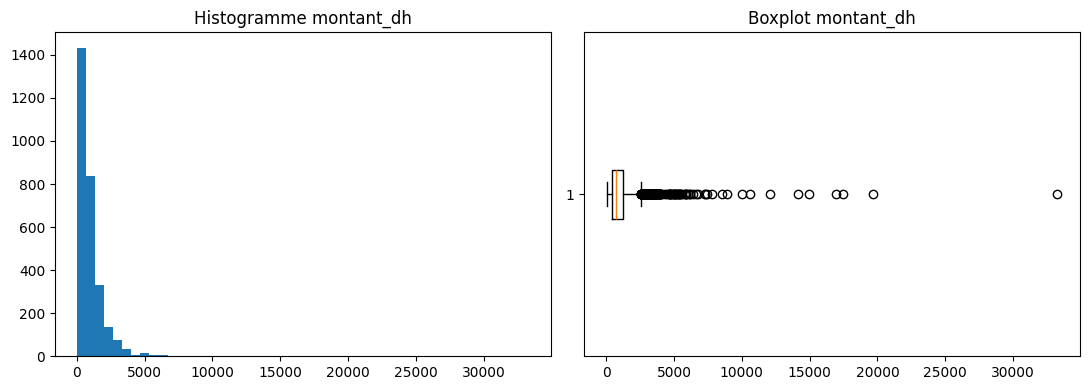

count     2893.000000
mean      1028.359457
std       1320.830647
min         36.410000
25%        389.530000
50%        708.660000
75%       1249.480000
max      33281.230000
Name: montant_dh, dtype: float64


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(df["montant_dh"].dropna(), bins=50); ax[0].set_title("Histogramme montant_dh")
ax[1].boxplot(df["montant_dh"].dropna(), vert=False); ax[1].set_title("Boxplot montant_dh")
plt.tight_layout(); plt.show()
print(df["montant_dh"].describe())

In [7]:
q1, q3 = df["montant_dh"].quantile([0.25, 0.75])
seuil = q3 + 1.5 * (q3 - q1)
print("Seuil boxplot :", round(seuil, 2))
extremes = df[df["montant_dh"] > seuil]
print("Nombre de montants extrêmes :", len(extremes))
display(extremes.sort_values("montant_dh", ascending=False).head(10)[["id_operation", "montant_dh", "fraude"]])

Seuil boxplot : 2539.41
Nombre de montants extrêmes : 184


,id_operation,montant_dh,fraude
2660,OP02851,33281.23,0
539,OP02169,19658.42,0
1775,OP00087,17496.64,0
1557,OP02211,16962.99,0
2556,OP02832,14951.95,0
65,OP02462,14135.85,0
1010,OP01376,12046.21,0
32,OP00591,10598.93,0
1313,OP02983,10028.37,0
2145,OP00127,8910.60,0


In [9]:
print(df.columns.tolist())
print("Identifiants :", ["id_operation", "id_client"])
print(df["resultat_enquete"].value_counts(dropna=False))
display(pd.crosstab(df["resultat_enquete"], df["fraude"]))

['id_operation', 'id_client', 'montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure', 'canal', 'appareil', 'region', 'international', 'resultat_enquete', 'fraude']
Identifiants : ['id_operation', 'id_client']
resultat_enquete
aucune_fraude       2742
fraude_confirmee     258
Name: count, dtype: int64


fraude,0,1
resultat_enquete,,
aucune_fraude,2742,0
fraude_confirmee,0,258


fraude
0    0.914
1    0.086
Name: proportion, dtype: float64


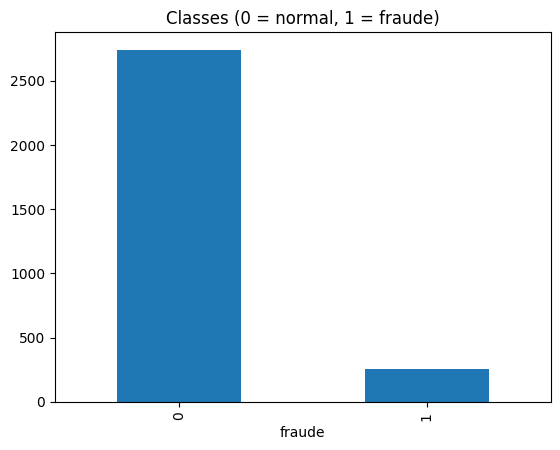

In [8]:
print(df["fraude"].value_counts(normalize=True))
df["fraude"].value_counts().plot(kind="bar", title="Classes (0 = normal, 1 = fraude)")
plt.show()

In [10]:
y = df["fraude"]
X = df.drop(columns=["id_operation", "id_client", "resultat_enquete", "fraude"])

In [11]:
print("X :", X.shape)
print("Colonnes de X :", X.columns.tolist())
print(y.value_counts())
print(y.value_counts(normalize=True).round(4))

X : (3000, 8)
Colonnes de X : ['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure', 'canal', 'appareil', 'region', 'international']
fraude
0    2742
1     258
Name: count, dtype: int64
fraude
0    0.914
1    0.086
Name: proportion, dtype: float64


In [12]:
X_ref, X_ver, y_ref, y_ver = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

In [13]:
print("Référence    :", X_ref.shape, "| fraude :", round(y_ref.mean() * 100, 2), "%")
print("Vérification :", X_ver.shape, "| fraude :", round(y_ver.mean() * 100, 2), "%")
print("Fichier complet | fraude :", round(y.mean() * 100, 2), "%")

Référence    : (2400, 8) | fraude : 8.58 %
Vérification : (600, 8) | fraude : 8.67 %
Fichier complet | fraude : 8.6 %


In [15]:
num_cols = ["montant_dh", "anciennete_mois", "nb_ops_24h", "heure"]
cat_cols = ["canal", "appareil", "region", "international"]

print("Numériques   :", num_cols)
print("Catégorielles:", cat_cols)

Numériques   : ['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure']
Catégorielles: ['canal', 'appareil', 'region', 'international']


In [16]:
num_pipe = Pipeline([
    ("imp", SimpleImputer(strategy="median")),
    ("sc", StandardScaler()),
])

In [17]:
num_pipe.fit(X_ref[num_cols])

Pipeline(steps=[('imp', SimpleImputer(strategy='median')),
                ('sc', StandardScaler())])

In [18]:
print("Médianes (référence) :", dict(zip(num_cols, num_pipe["imp"].statistics_.round(2))))
print("Échelle  (référence) :", dict(zip(num_cols, num_pipe["sc"].scale_.round(2))))

Médianes (référence) : {'montant_dh': np.float64(710.79), 'anciennete_mois': np.float64(87.0), 'nb_ops_24h': np.float64(3.0), 'heure': np.float64(11.0)}
Échelle  (référence) : {'montant_dh': np.float64(1327.63), 'anciennete_mois': np.float64(49.49), 'nb_ops_24h': np.float64(1.65), 'heure': np.float64(7.0)}


In [19]:
cat_pipe = Pipeline([
    ("imp", SimpleImputer(strategy="most_frequent")),
    ("oh", OneHotEncoder(handle_unknown="ignore")),
])

In [21]:
prep = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
])

In [22]:
Xr = prep.fit_transform(X_ref)
Xv = prep.transform(X_ver)

In [23]:
print("Référence    :", Xr.shape)
print("Vérification :", Xv.shape)

Référence    : (2400, 18)
Vérification : (600, 18)


In [24]:
rob_num = Pipeline([
    ("imp", SimpleImputer(strategy="median")),
    ("sc", RobustScaler()),
])
prep_rob = ColumnTransformer([
    ("num", rob_num, num_cols),
    ("cat", cat_pipe, cat_cols),
])
prep_rob.fit(X_ref)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imp',
                                                  SimpleImputer(strategy='median')),
                                                 ('sc', RobustScaler())]),
                                 ['montant_dh', 'anciennete_mois', 'nb_ops_24h',
                                  'heure']),
                                ('cat',
                                 Pipeline(steps=[('imp',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('oh',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['canal', 'appareil', 'region',
                                  'international'])])

In [25]:
ordinaire = X_ref.iloc[[(X_ref["montant_dh"] - X_ref["montant_dh"].median()).abs().argmin()]]
extreme = X_ref.iloc[[X_ref["montant_dh"].argmax()]]

In [26]:
i = num_cols.index("montant_dh")   # position de montant_dh (0)
for nom, ligne in [("ordinaire", ordinaire), ("extrême", extreme)]:
    s = prep.transform(ligne)[0, i]       # StandardScaler (prep de Q12)
    r = prep_rob.transform(ligne)[0, i]   # RobustScaler
    print(f"{nom}: montant={ligne['montant_dh'].iloc[0]:.1f} | Standard={s:.2f} | Robust={r:.2f}")

ordinaire: montant=710.3 | Standard=-0.23 | Robust=-0.00
extrême: montant=33281.2 | Standard=24.30 | Robust=39.89


In [27]:
q1 = X_ref["montant_dh"].quantile(0.25)
q3 = X_ref["montant_dh"].quantile(0.75)
iqr = q3 - q1

print("Q1  :", round(q1, 2))
print("Q3  :", round(q3, 2))
print("IQR :", round(iqr, 2))

Q1  : 393.1
Q3  : 1249.88
IQR : 856.78


In [28]:
borne_basse = q1 - 1.5 * iqr
borne_haute = q3 + 1.5 * iqr
print("Borne basse :", round(borne_basse, 2))
print("Borne haute :", round(borne_haute, 2))

Borne basse : -892.08
Borne haute : 2535.05


In [29]:
masque = (X_ref["montant_dh"] < borne_basse) | (X_ref["montant_dh"] > borne_haute)
atypiques = X_ref[masque].copy()
atypiques["fraude"] = y_ref[masque]

print("Nombre de lignes concernées :", masque.sum(), "sur", len(X_ref))
print("Sous la borne basse :", (X_ref["montant_dh"] < borne_basse).sum())
print("Au-dessus de la borne haute :", (X_ref["montant_dh"] > borne_haute).sum())

Nombre de lignes concernées : 146 sur 2400
Sous la borne basse : 0
Au-dessus de la borne haute : 146


In [30]:
display(atypiques.sort_values("montant_dh", ascending=False).head(5)[["montant_dh", "canal", "international", "heure", "fraude"]])
print("Fraude parmi les atypiques :", round(atypiques["fraude"].mean() * 100, 1), "%")
print("Fraude dans la référence   :", round(y_ref.mean() * 100, 1), "%")

,montant_dh,canal,international,heure,fraude
2660,33281.23,application,non,17,0
539,19658.42,application,non,11,0
1775,17496.64,site_web,non,3,0
2556,14951.95,application,non,6,0
65,14135.85,application,non,14,0


Fraude parmi les atypiques : 11.6 %
Fraude dans la référence   : 8.6 %


In [31]:
montant_original = X_ref["montant_dh"]
montant_limite = X_ref["montant_dh"].clip(lower=borne_basse, upper=borne_haute)

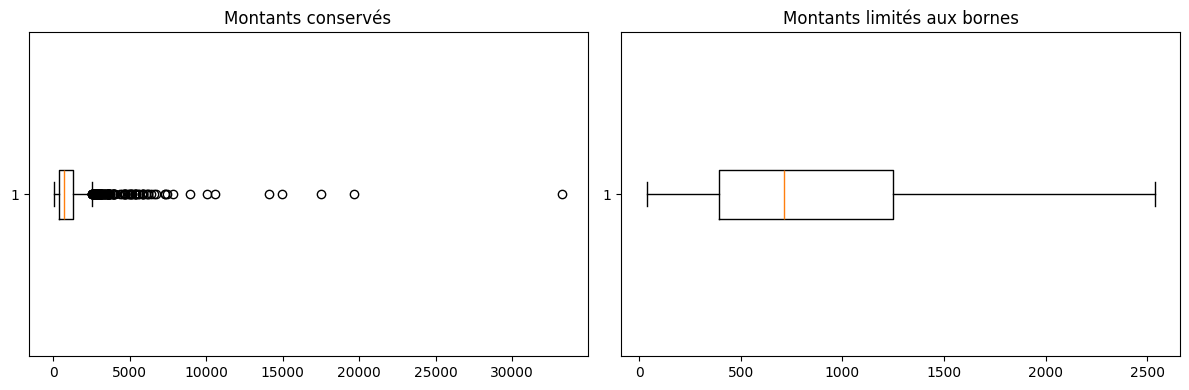

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].boxplot(montant_original.dropna(), vert=False)
ax[0].set_title("Montants conservés")
ax[1].boxplot(montant_limite.dropna(), vert=False)
ax[1].set_title("Montants limités aux bornes")
plt.tight_layout(); plt.show()

In [33]:
from sklearn.preprocessing import MinMaxScaler

In [34]:
imp = SimpleImputer(strategy="median")
m_ref = imp.fit_transform(X_ref[["montant_dh"]])
m_ver = imp.transform(X_ver[["montant_dh"]])

In [36]:
display(resultats.describe().round(3))
display(resultats.sort_values("original").iloc[[0, len(resultats)//2, -1]].round(3))

,original,MinMax,Standard,Robust
count,600.000,600.000,600.000,600.000
mean,1002.472,0.029,-0.014,0.357
std,1173.865,0.035,0.884,1.438
min,61.780,0.001,-0.722,-0.795
25%,381.100,0.010,-0.482,-0.404
50%,710.790,0.020,-0.233,0.000
75%,1221.340,0.036,0.151,0.625
max,16962.990,0.509,12.008,19.906


,original,MinMax,Standard,Robust
511,61.78,0.001,-0.722,-0.795
348,710.79,0.020,-0.233,0.000
224,16962.99,0.509,12.008,19.906


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [35]:
scalers = {
    "MinMax": MinMaxScaler(),
    "Standard": StandardScaler(),
    "Robust": RobustScaler(),
}

resultats = pd.DataFrame({"original": m_ver.ravel()})
for nom, sc in scalers.items():
    sc.fit(m_ref)
    resultats[nom] = sc.transform(m_ver).ravel()

In [37]:
montants = pd.DataFrame({"montant_dh": [400.0, 710.79, 1200.0, X_ref["montant_dh"].max()]})

In [38]:
tableau = montants.copy()
for nom, sc in scalers.items():
    tableau[nom] = sc.transform(montants[["montant_dh"]]).ravel()

display(tableau.round(3))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MinMaxScaler was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RobustScaler was fitted without feature names
  warnings.warn(


,montant_dh,MinMax,Standard,Robust
0,400.00,0.011,-0.468,-0.381
1,710.79,0.020,-0.233,0.000
2,1200.00,0.035,0.135,0.599
3,33281.23,1.000,24.299,39.893


In [39]:
transformes = {nom: sc.transform(m_ref).ravel() for nom, sc in scalers.items()}

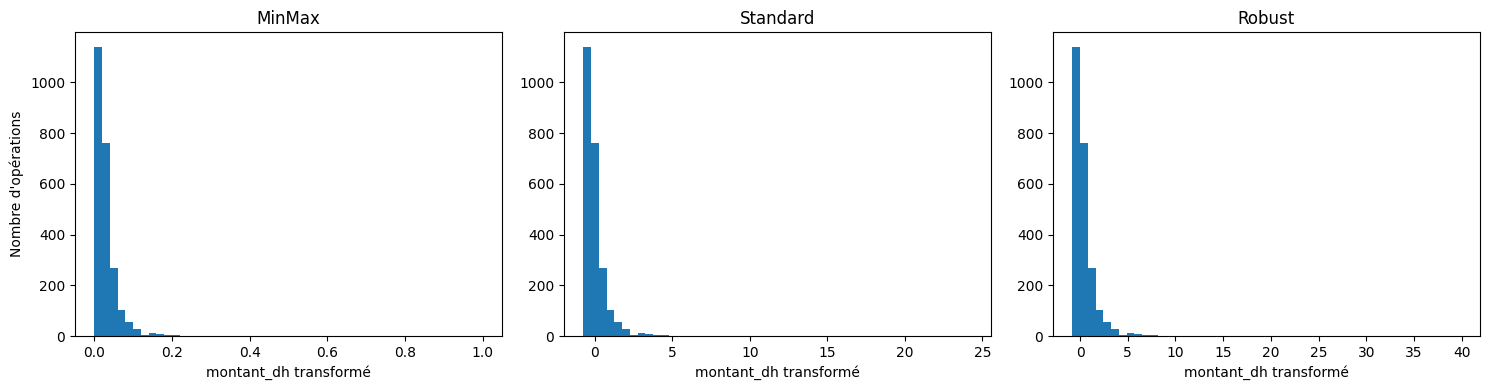

In [40]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (nom, valeurs) in zip(ax, transformes.items()):
    a.hist(valeurs, bins=50)
    a.set_title(nom)
    a.set_xlabel("montant_dh transformé")
ax[0].set_ylabel("Nombre d'opérations")
plt.tight_layout(); plt.show()

In [41]:
mm = MinMaxScaler().fit(X_ref[["montant_dh"]].dropna())
print("Min référence :", mm.data_min_[0])
print("Max référence :", mm.data_max_[0])

Min référence : 36.41
Max référence : 33281.23


In [42]:
exemple = pd.DataFrame({"montant_dh": [X_ref["montant_dh"].max(), 40000.0, 66562.46]})
exemple["MinMax"] = mm.transform(exemple[["montant_dh"]]).ravel()
display(exemple)

,montant_dh,MinMax
0,33281.23,1.000000
1,40000.00,1.202100
2,66562.46,2.001095


In [43]:
compte = y_ref.value_counts()
print(compte)

fraude
0    2194
1     206
Name: count, dtype: int64


In [44]:
rapport = compte[0] / compte[1]
print("Rapport classe 0 / classe 1 :", round(rapport, 2))
print("Soit environ 1 fraude pour", round(rapport), "opérations normales")

Rapport classe 0 / classe 1 : 10.65
Soit environ 1 fraude pour 11 opérations normales


In [45]:
from imblearn.over_sampling import RandomOverSampler

In [46]:
ros = RandomOverSampler(random_state=42)
X_ref_os, y_ref_os = ros.fit_resample(X_ref, y_ref)

print("Avant :", y_ref.value_counts().to_dict(), "| lignes :", len(y_ref))
print("Après :", y_ref_os.value_counts().to_dict(), "| lignes :", len(y_ref_os))

Avant : {0: 2194, 1: 206} | lignes : 2400
Après : {0: 2194, 1: 2194} | lignes : 4388


In [47]:
nouvelles = X_ref_os.iloc[len(X_ref):]        # lignes ajoutées à la fin
print("Nombre de lignes ajoutées :", len(nouvelles))
print("Toutes de la classe fraude = 1 ?", (y_ref_os.iloc[len(X_ref):] == 1).all())
print("Doublons dans X_ref avant :", X_ref.duplicated().sum())
print("Doublons dans X_ref_os après :", X_ref_os.duplicated().sum())

Nombre de lignes ajoutées : 1988
Toutes de la classe fraude = 1 ? True
Doublons dans X_ref avant : 0
Doublons dans X_ref_os après : 1988


In [48]:
from imblearn.under_sampling import RandomUnderSampler

In [49]:
rus = RandomUnderSampler(random_state=42)
X_ref_us, y_ref_us = rus.fit_resample(X_ref, y_ref)

print("Avant :", y_ref.value_counts().to_dict(), "| lignes :", len(y_ref))
print("Après :", y_ref_us.value_counts().to_dict(), "| lignes :", len(y_ref_us))

Avant : {0: 2194, 1: 206} | lignes : 2400
Après : {0: 206, 1: 206} | lignes : 412


In [50]:
print("Lignes conservées :", len(y_ref_us))
print("Lignes supprimées :", len(y_ref) - len(y_ref_us))

Lignes conservées : 412
Lignes supprimées : 1988


In [51]:
from imblearn.over_sampling import SMOTE

In [52]:
d = X_ref[["montant_dh", "anciennete_mois"]].dropna()
yd = y_ref.loc[d.index]
fraudes = d[yd == 1]

In [53]:
A = fraudes.iloc[0]          # observation réelle 1 (fraude)
B = fraudes.iloc[1]          # observation réelle 2 (fraude)
lam = 0.5                    # entre 0 et 1 (SMOTE le tire au hasard)
S = A + lam * (B - A)        # point synthétique entre A et B

print("A (réelle)     :", A.values)
print("B (réelle)     :", B.values)
print("S (synthétique):", S.values)

A (réelle)     : [433.29  11.  ]
B (réelle)     : [1624.43  129.  ]
S (synthétique): [1028.86   70.  ]


In [54]:
sm = SMOTE(random_state=42)
Xs, ys = sm.fit_resample(d, yd)

print("Avant :", yd.value_counts().to_dict())
print("Après :", ys.value_counts().to_dict())

nouvelles = Xs.iloc[len(d):]                                   # lignes ajoutées
print("Nouvelles lignes :", len(nouvelles))
print("Copies de lignes existantes :", nouvelles.merge(d, how="inner").shape[0])
display(nouvelles.head(3).round(2))

Avant : {0: 2023, 1: 192}
Après : {0: 2023, 1: 2023}
Nouvelles lignes : 1831
Copies de lignes existantes : 0


,montant_dh,anciennete_mois
2215,1231.53,23.95
2216,210.78,58.37
2217,251.45,83.85


In [55]:
tableau_classes = pd.DataFrame({
    "Référence avant":        y_ref.value_counts(),
    "Référence après sur-éch.": y_ref_os.value_counts(),
    "Référence après sous-éch.": y_ref_us.value_counts(),
    "Vérification (inchangée)": y_ver.value_counts(),
}).rename(index={0: "Classe 0 (normal)", 1: "Classe 1 (fraude)"})

tableau_classes.loc["Total"] = tableau_classes.sum()
tableau_classes.loc["% fraude"] = (
    tableau_classes.loc["Classe 1 (fraude)"] / tableau_classes.loc["Total"] * 100
).round(2)

display(tableau_classes)

# Vérification : le groupe de vérification n'a pas bougé
print("y_ver inchangé :", y_ver.value_counts().to_dict())

,Référence avant,Référence après sur-éch.,Référence après sous-éch.,Vérification (inchangée)
fraude,,,,
Classe 0 (normal),2194.00,2194.0,206.0,548.00
Classe 1 (fraude),206.00,2194.0,206.0,52.00
Total,2400.00,4388.0,412.0,600.00
% fraude,8.58,50.0,50.0,8.67


y_ver inchangé : {0: 548, 1: 52}


In [56]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder

num_cols = ["montant_dh", "anciennete_mois", "nb_ops_24h", "heure"]
cat_cols = ["canal", "appareil", "region", "international"]

# Nombres : médiane + RobustScaler
num_final = Pipeline([
    ("imp", SimpleImputer(strategy="median")),
    ("sc", RobustScaler()),
])

# Catégories : modalité la plus fréquente + OneHotEncoder
cat_final = Pipeline([
    ("imp", SimpleImputer(strategy="most_frequent")),
    ("oh", OneHotEncoder(handle_unknown="ignore")),
])

prep_final = ColumnTransformer([
    ("num", num_final, num_cols),
    ("cat", cat_final, cat_cols),
])

# Apprentissage sur la référence uniquement, puis application aux deux groupes
Xr_final = prep_final.fit_transform(X_ref)
Xv_final = prep_final.transform(X_ver)

print("Référence    :", Xr_final.shape)
print("Vérification :", Xv_final.shape)
print("Colonnes de sortie :", prep_final.get_feature_names_out().tolist())
print("NaN restants (réf.) :", pd.isna(Xr_final.toarray() if hasattr(Xr_final, "toarray") else Xr_final).sum())

Référence    : (2400, 18)
Vérification : (600, 18)
Colonnes de sortie : ['num__montant_dh', 'num__anciennete_mois', 'num__nb_ops_24h', 'num__heure', 'cat__canal_agence', 'cat__canal_application', 'cat__canal_site_web', 'cat__canal_telephone', 'cat__appareil_mobile', 'cat__appareil_ordinateur', 'cat__appareil_terminal', 'cat__region_Autre', 'cat__region_Casablanca-Settat', 'cat__region_Draa-Tafilalet', 'cat__region_Marrakech-Safi', 'cat__region_Souss-Massa', 'cat__international_non', 'cat__international_oui']
NaN restants (réf.) : 0


In [57]:

# 1. Paramètres calculés sur la référence UNIQUEMENT
prep_final.fit(X_ref)

# 2. Même transformateur appliqué aux deux groupes
Xr_final = prep_final.transform(X_ref)
Xv_final = prep_final.transform(X_ver)

# 3. Passage en tableau dense si nécessaire (OneHot peut renvoyer du sparse)
Xr_arr = Xr_final.toarray() if hasattr(Xr_final, "toarray") else Xr_final
Xv_arr = Xv_final.toarray() if hasattr(Xv_final, "toarray") else Xv_final

# 4. Vérification du nombre de colonnes
noms = prep_final.get_feature_names_out()
print("Référence    :", Xr_arr.shape)
print("Vérification :", Xv_arr.shape)
print("Même nombre de colonnes ?", Xr_arr.shape[1] == Xv_arr.shape[1] == len(noms))
print("Colonnes :", noms.tolist())

# 5. Vérification des valeurs manquantes
print("NaN avant (X_ref) :", int(X_ref.isna().sum().sum()))
print("NaN après référence    :", int(np.isnan(Xr_arr).sum()))
print("NaN après vérification :", int(np.isnan(Xv_arr).sum()))

# 6. Quelques paramètres appris sur la référence
print("Médianes :", dict(zip(num_cols, prep_final.named_transformers_["num"]["imp"].statistics_.round(2))))
print("Centres RobustScaler (médiane) :", dict(zip(num_cols, prep_final.named_transformers_["num"]["sc"].center_.round(2))))
print("Échelles RobustScaler (IQR)    :", dict(zip(num_cols, prep_final.named_transformers_["num"]["sc"].scale_.round(2))))
print("Modalités fréquentes :", dict(zip(cat_cols, prep_final.named_transformers_["cat"]["imp"].statistics_)))

Référence    : (2400, 18)
Vérification : (600, 18)
Même nombre de colonnes ? True
Colonnes : ['num__montant_dh', 'num__anciennete_mois', 'num__nb_ops_24h', 'num__heure', 'cat__canal_agence', 'cat__canal_application', 'cat__canal_site_web', 'cat__canal_telephone', 'cat__appareil_mobile', 'cat__appareil_ordinateur', 'cat__appareil_terminal', 'cat__region_Autre', 'cat__region_Casablanca-Settat', 'cat__region_Draa-Tafilalet', 'cat__region_Marrakech-Safi', 'cat__region_Souss-Massa', 'cat__international_non', 'cat__international_oui']
NaN avant (X_ref) : 529
NaN après référence    : 0
NaN après vérification : 0
Médianes : {'montant_dh': np.float64(710.79), 'anciennete_mois': np.float64(87.0), 'nb_ops_24h': np.float64(3.0), 'heure': np.float64(11.0)}
Centres RobustScaler (médiane) : {'montant_dh': np.float64(710.79), 'anciennete_mois': np.float64(87.0), 'nb_ops_24h': np.float64(3.0), 'heure': np.float64(11.0)}
Échelles RobustScaler (IQR)    : {'montant_dh': np.float64(816.45), 'anciennete_moi

In [58]:
from sklearn.preprocessing import OneHotEncoder

# 1. Ligne simulée : on copie une vraie ligne et on remplace le canal par une modalité jamais vue
ligne_inconnue = X_ref.iloc[[0]].copy()
print("Canaux connus (référence) :", sorted(X_ref["canal"].dropna().unique()))
ligne_inconnue["canal"] = "crypto"          # modalité absente de la référence
display(ligne_inconnue)

# 2. Transformation avec le transformateur final (handle_unknown="ignore")
sortie = prep_final.transform(ligne_inconnue)
sortie = sortie.toarray() if hasattr(sortie, "toarray") else sortie
noms = prep_final.get_feature_names_out()

print("Transformation réussie, forme :", sortie.shape)
print("Colonnes 'canal' :")
for n, v in zip(noms, sortie[0]):
    if n.startswith("cat__canal"):
        print(f"  {n} = {v}")

# 3. Comparaison : même encodeur SANS handle_unknown="ignore"
oh_strict = OneHotEncoder().fit(X_ref[["canal"]].dropna())
try:
    oh_strict.transform(ligne_inconnue[["canal"]])
except ValueError as e:
    print("Sans handle_unknown='ignore' -> ValueError :", e)

Canaux connus (référence) : ['agence', 'application', 'site_web', 'telephone']


,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international
384,419.53,53.0,3.0,16,crypto,mobile,Draa-Tafilalet,oui


Transformation réussie, forme : (1, 18)
Colonnes 'canal' :
  cat__canal_agence = 0.0
  cat__canal_application = 0.0
  cat__canal_site_web = 0.0
  cat__canal_telephone = 0.0
Sans handle_unknown='ignore' -> ValueError : Found unknown categories ['crypto'] in column 0 during transform


In [59]:
import joblib
import os

# 1. Enregistrement du transformateur déjà ajusté sur la référence
joblib.dump(prep_final, "prep_final.joblib")
print("Fichier enregistré :", os.path.getsize("prep_final.joblib"), "octets")

# 2. Rechargement (aucun fit n'est appelé)
prep_charge = joblib.load("prep_final.joblib")

# 3. Petit échantillon du groupe de vérification
echantillon = X_ver.head(10)

sortie_originale = prep_final.transform(echantillon)
sortie_rechargee = prep_charge.transform(echantillon)

# Passage en tableau dense
if hasattr(sortie_originale, "toarray"):
    sortie_originale = sortie_originale.toarray()
    sortie_rechargee = sortie_rechargee.toarray()

# 4. Comparaison des valeurs
print("Forme :", sortie_rechargee.shape)
print("Valeurs identiques ?", np.array_equal(sortie_originale, sortie_rechargee))
print("Écart maximal :", np.abs(sortie_originale - sortie_rechargee).max())

# 5. Comparaison des paramètres appris (médianes et échelles) : ils sont restaurés, pas recalculés
num_orig = prep_final.named_transformers_["num"]
num_charge = prep_charge.named_transformers_["num"]
print("Médianes identiques ?", np.array_equal(num_orig["imp"].statistics_, num_charge["imp"].statistics_))
print("Centres identiques ?", np.array_equal(num_orig["sc"].center_, num_charge["sc"].center_))
print("Échelles identiques ?", np.array_equal(num_orig["sc"].scale_, num_charge["sc"].scale_))


Fichier enregistré : 4358 octets
Forme : (10, 18)
Valeurs identiques ? True
Écart maximal : 0.0
Médianes identiques ? True
Centres identiques ? True
Échelles identiques ? True


In [60]:
import pandas as pd
from sklearn.impute import SimpleImputer

m = X_ref[["montant_dh"]]

# 1. Imputation par la moyenne et par la médiane (paramètres appris sur la référence)
imp_moy = SimpleImputer(strategy="mean").fit(m)
imp_med = SimpleImputer(strategy="median").fit(m)

moyenne = imp_moy.statistics_[0]
mediane = imp_med.statistics_[0]
print("Moyenne :", round(moyenne, 2))
print("Médiane :", round(mediane, 2))
print("Part des montants sous la moyenne :", round((m["montant_dh"].dropna() < moyenne).mean() * 100, 1), "%")

# 2. Test de résistance : on retire le plus gros montant, puis on en ajoute un énorme
serie = m["montant_dh"].dropna()
sans_max = serie.drop(serie.idxmax())

test = pd.DataFrame({
    "Situation": ["Référence", "Sans le maximum (33 281)", "+ un montant de 100 000", "+ un montant de 1 000 000"],
    "Moyenne": [
        serie.mean(),
        sans_max.mean(),
        pd.concat([serie, pd.Series([100_000])]).mean(),
        pd.concat([serie, pd.Series([1_000_000])]).mean(),
    ],
    "Médiane": [
        serie.median(),
        sans_max.median(),
        pd.concat([serie, pd.Series([100_000])]).median(),
        pd.concat([serie, pd.Series([1_000_000])]).median(),
    ],
}).round(2)
display(test)

Moyenne : 1032.47
Médiane : 710.79
Part des montants sous la moyenne : 67.0 %


,Situation,Moyenne,Médiane
0,Référence,1032.47,710.79
1,Sans le maximum (33 281),1018.51,710.29
2,+ un montant de 100 000,1075.26,711.29
3,+ un montant de 1 000 000,1464.36,711.29
